In [36]:
import numpy as np
import matplotlib.pyplot as plt

Ecuación de Poisson en simetría esférica:
\begin{align*}
    \frac{1}{r^2} \frac{d}{dr}\left(r^2 \frac{d\Phi}{dr}\right) = 4\pi G \rho(r)
\end{align*}
Con:
\begin{align*}
    \rho(r) = \rho_c \left[1 - \left(\frac{r}{R}\right)^2 \right], \quad \rho_c = 10^5 \text{ kg/m$^3$}, \quad R = 7\times10^8 \text{ m}
\end{align*}
La solución analítica es:
\begin{align*}
    \Phi(r) = -4\pi G \rho_c \left( \frac{7R^2}{60} - \frac{r^2}{6} + \frac{r^4}{20R^2} \right)
\end{align*}


g_exac_R = -7827.676 m/s^2.

n = 10, L2 = 3.524e-03 (ratio    -), g_surf = -8474.49, g_eps = 8.26% (ratio    -)
n = 20, L2 = 1.004e-03 (ratio 3.51), g_surf = -8184.12, g_eps = 4.55% (ratio 1.81)
n = 40, L2 = 2.692e-04 (ratio 3.73), g_surf = -8014.52, g_eps = 2.39% (ratio 1.91)


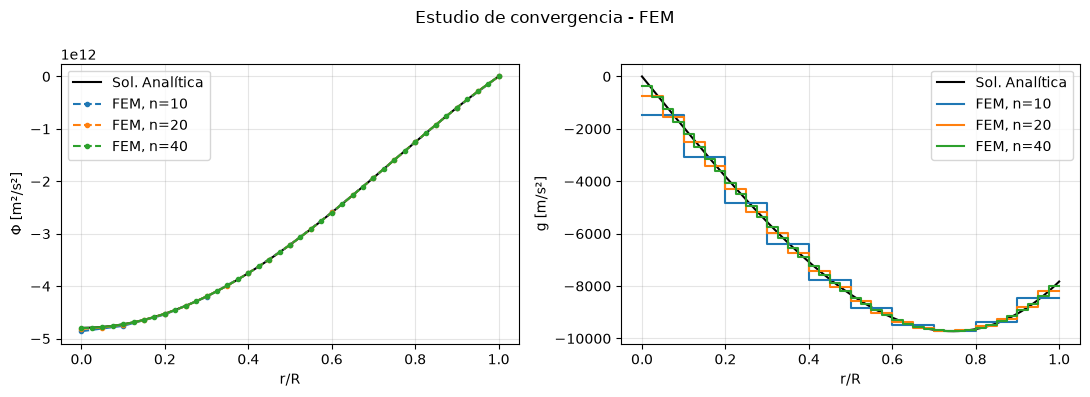

In [37]:
# =====================================================
# MÓDULO 1: MALLA Y PARÁMETROS
# =====================================================

# ------ CONSTANTES ------
R = 7e8       # m
rho_c = 1e5   # kg / m^3
G = 6.674e-11 # N m^2 / kg^2
Phi_R = 0.0   # Dirichlet

# ------ PARÁMETROS NUMÉRICOS ------
n = [10, 20, 40]

# =====================================================
# MÓDULO 2: ENSAMBLADO
# =====================================================

# Solucionar por Thomas: K * Phi = f
def thomas(inf, pri, sup, f):
    N   = len(pri)
    c   = np.zeros(N - 1)
    dd  = np.zeros(N)
    Phi = np.zeros(N)

    c[0]  = sup[0] / pri[0]
    dd[0] = f[0] / pri[0]

    for i in range(1, N):
        m = pri[i] - inf[i - 1] * c[i - 1]
        if i < N - 1:
            c[i] = sup[i] / m
        dd[i] = (f[i] - inf[i - 1] * dd[i - 1]) / m
    
    Phi[-1] = dd[-1]

    for i in range(N - 2, -1, -1):
        Phi[i] = dd[i] - c[i] * Phi[i + 1]

    return Phi

def assembly(n):
    h = R / n
    r = np.linspace(0, R, n + 1)
    K_sup = np.zeros(n)
    K_pri = np.zeros(n + 1)
    K_inf = np.zeros(n)
    f = np.zeros(n + 1)
    c = -4 * np.pi * G * rho_c 

    for k in range(0, n):
        r_curr, r_next = r[k], r[k + 1]
        K_e = (r_next**3 - r_curr**3) / (3 * h**2) * np.array([[1, -1], [-1, 1]])

        I = lambda p: (r_next**(p+1) - r_curr**(p+1)) / (p+1)

        f_e0 = c * ( (r_next*I(2) - I(3))/h - (r_next*I(4) - I(5))/(h * R**2) )
        f_e1 = c * ( (I(3) - r_curr*I(2))/h - (I(5) - r_curr*I(4))/(h * R**2) )

        # Ensamblaje:
        K_sup[k]     += K_e[0, 1]
        K_pri[k]     += K_e[0, 0] 
        K_pri[k + 1] += K_e[1, 1]
        K_inf[k]     += K_e[1, 0]

        f[k]     += f_e0
        f[k + 1] += f_e1
    # Dirichlet:
    f[n - 1] += - K_sup[n - 1] * Phi_R
    K_sup[n - 1] = 0.0 
    K_inf[n - 1] = 0.0
    K_pri[n] = 1.0
    f[n] = Phi_R

    Phi = thomas(K_inf, K_pri, K_sup, f)

    return r, Phi, h

# =====================================================
# MÓDULO 3: POST-PROCESAMIENTO Y CONVERGENCIA
# =====================================================

# ------ SOLUCIÓN ANALÍTICA ------
Phi_exac = lambda r: -4 * np.pi * G * rho_c * ( 7*R**2 / 60 - r**2 / 6 + r**4 / (20 * R**2) )
g_exac   = lambda r:  4 * np.pi * G * rho_c * ( -r/3 + r**3 / (5 * R**2))
g_exac_R = -8 * np.pi * G * rho_c * R / 15

def postprocess(r, Phi, h):
    n = len(r) - 1
    r_mid = np.zeros(n)
    Phi_mid = np.zeros(n)
    g_fem = np.zeros(n)

    for k in range(n):
        r_mid[k]   = 0.5 * (r[k] + r[k + 1])
        Phi_mid[k] = Phi[k] * (r[k + 1] - r_mid[k])/h + Phi[k + 1] * (r_mid[k] - r[k])/h
        g_fem[k]   = -(Phi[k + 1] - Phi[k])/h

    # Gravedad superficial:
    g_surf   = -(Phi[n] - Phi[n - 1])/h
    g_eps    = 100 * np.abs( (g_surf - g_exac_R)/g_exac_R ) 

    # Error L2 relativo:
    L2_err = np.sqrt(h * np.sum((Phi_mid - Phi_exac(r_mid))**2)) / np.sqrt(h * np.sum(Phi_exac(r_mid)**2))

    return r_mid, Phi_mid, g_fem, g_surf, g_eps, L2_err

# ------- Estudio de convergencia ------
results = {}
prev_L2 = prev_g = None
print(f'g_exac_R = {g_exac_R:.3f} m/s^2.\n')

for n_elem in n:
    r, Phi, h = assembly(n_elem)
    r_mid, Phi_mid, g_fem, g_surf, g_eps, L2_err = postprocess(r, Phi, h)
    rL2 = '   -' if prev_L2 is None else f'{prev_L2/L2_err:.2f}'
    rg  = '   -' if prev_g  is None else f'{prev_g/g_eps:.2f}'

    print(f'n = {n_elem}, L2 = {L2_err:.3e} (ratio {rL2}), g_surf = {g_surf:.2f}, g_eps = {g_eps:.2f}% (ratio {rg})')   

    prev_L2, prev_g = L2_err, g_eps
    results[n_elem] = (r, Phi, r_mid, g_fem)

# ------ Gráficas ------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
r_arr = np.linspace(0, R, 400)

ax1.plot(r_arr/R, Phi_exac(r_arr), 'k', label='Sol. Analítica')
ax2.plot(r_arr/R, g_exac(r_arr), 'k', label='Sol. Analítica')

for n_elem, (r, Phi, r_mid, g_fem) in results.items():
    ax1.plot(r/R, Phi, 'o--', ms=3, label=f'FEM, n={n_elem}')
    ax2.step(r/R, np.append(g_fem, g_fem[-1]), where='post', label=f'FEM, n={n_elem}')

ax1.set_xlabel("r/R"); ax1.set_ylabel("Φ [m²/s²]"); ax1.legend(); ax1.grid(color='gray', alpha=0.2)
ax2.set_xlabel("r/R"); ax2.set_ylabel("g [m/s²]");  ax2.legend(); ax2.grid(color='gray', alpha=0.2)

fig.suptitle('Estudio de convergencia - FEM')
plt.tight_layout()
plt.show()